<a href="https://colab.research.google.com/github/krishna-murari23/UGRP2026/blob/main/2D_Heat_Conduction_Inverse_Heat_Problems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case 1: 2D Steady-State Heat Conduction with Uniform Generation(Dirichlet BC)

**Problem.** Square plate, $1\text{ m}\times1\text{ m}$, thermal conductivity $k=238\ \text{W/m·K}$, uniform volumetric heat generation $\dot q = 10^6\ \text{W/m}^3$.

Governing equation:
$$\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}+\frac{\dot q}{k}=0,\qquad (x,y)\in(0,1)^2$$

Dirichlet boundary conditions:
$$T(0,y)=700\text{ K},\qquad T(1,y)=T(x,0)=T(x,1)=350\text{ K}$$


1. **Only the ratio $\beta=\dot q/k$ is estimated** and not $k$ and $\dot q$ separately. As derived before, the governing equation and the Dirichlet boundary conditions never involve $k$ and $\dot q$ individually, only their ratio , so $\beta$ is the only physically identifiable quantity from temperature data
2. **Only a sparse set of interior points is used as data**


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)

T_left = 700.0
T_other = 300.0
k_true = 238.0
q_true = 1e6
beta_true = q_true / k_true    # known only for checking the result -- never used in training

print(f"beta_true = q/k = {beta_true:.2f}")

beta_true = q/k = 4201.68


## Analaytical Solution

In [ ]:
a = q_true/(2*k_true)
B = -(T_left - T_other) + a

def T_particular(x):
    return -a*x**2 + B*x + T_left

def g(x):
    return T_other - T_particular(x)

def g_n(n):
    base = -2*(T_left - T_other)/(n*np.pi)
    if n % 2 == 0:
        return base
    return base - 8*a/(n**3*np.pi**3)

def T_analytical(x, y, N=200):
    T = T_particular(x)
    for n in range(1, N+1):
        T += g_n(n) * np.cosh(n*np.pi*(y-0.5))/np.cosh(n*np.pi/2) * np.sin(n*np.pi*x)
    return T

##Interior Sparse Points
 A $7\times7$ grid of points is placed *strictly inside* the plate (away from the boundary and the two singular corners), and each one gets a single noisy temperature reading

In [ ]:
rng = np.random.default_rng(42)

n_s = 7
xs_s = np.linspace(0.15, 0.85, n_s)
ys_s = np.linspace(0.15, 0.85, n_s)
Xs_grid, Ys_grid = np.meshgrid(xs_s, ys_s)
sensor_pts = np.stack([Xs_grid.ravel(), Ys_grid.ravel()], axis=1)

T_clean = np.array([T_analytical(x, y) for x, y in sensor_pts])
noise_sigma = 0.5   # K, modest measurement nois
T_noisy = T_clean + rng.normal(0, noise_sigma, size=T_clean.shape)

print(f"number of sensor points used as data: {sensor_pts.shape[0]}")
print(f"sensor x range: [{sensor_pts[:,0].min():.2f}, {sensor_pts[:,0].max():.2f}]  "
      f"(plate spans [0,1] -- sensors stay well inside)")
print(f"sensor y range: [{sensor_pts[:,1].min():.2f}, {sensor_pts[:,1].max():.2f}]")
print(f"a sample reading: T({sensor_pts[0,0]:.2f}, {sensor_pts[0,1]:.2f}) = {T_noisy[0]:.2f} K "
      f"(clean value was {T_clean[0]:.2f} K)")

number of sensor points used as data: 49
sensor x range: [0.15, 0.85]  (plate spans [0,1] -- sensors stay well inside)
sensor y range: [0.15, 0.85]
a sample reading: T(0.15, 0.15) = 589.49 K (clean value was 589.34 K)


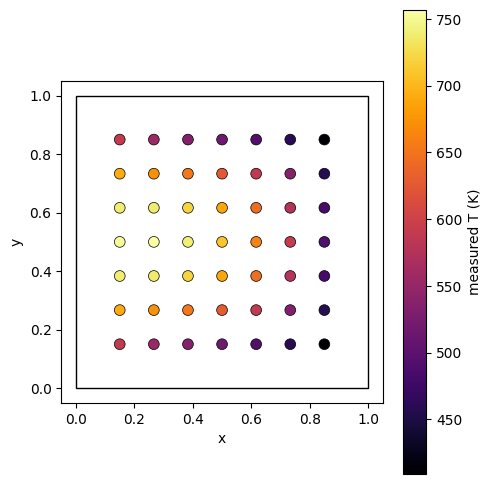

In [ ]:
fig, ax = plt.subplots(figsize=(5,5))
ax.add_patch(plt.Rectangle((0,0), 1, 1, fill=False, edgecolor='black'))
ax.scatter(sensor_pts[:,0], sensor_pts[:,1], c=T_noisy, cmap='inferno', s=60, edgecolor='k', linewidth=0.5)
ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05); ax.set_aspect('equal')
ax.set_xlabel('x'); ax.set_ylabel('y')
plt.colorbar(ax.collections[0], label='measured T (K)')
plt.tight_layout(); plt.show()

##Different point types

- **Boundary points** @ the edges of the plate. Their temperatures ($700$ K on the left, $300$ K elsewhere) are given
- **Sensor points** — the 49 interior points

Nondimensionalize the two boundary temperatures:
$$\Delta T = T_{\text{left}}-T_{\text{other}} = 400\text{ K}, \qquad \theta = \frac{T-300}{400}$$

Substituting into the PDE gives a single unknown dimensionless coefficient:
$$\theta_{xx}+\theta_{yy}+\lambda = 0, \qquad \lambda := \frac{\dot q}{k\,\Delta T} = \frac{\beta}{\Delta T}$$.

In [ ]:
dT_scale = T_left - T_other    # 400 K -- from the known BCs, not from k or q
T_ref = T_other

sensor_pts_t   = torch.tensor(sensor_pts, dtype=torch.float32)
theta_sensor_t = torch.tensor((T_noisy - T_ref)/dT_scale, dtype=torch.float32)

n_side = 25
xs = torch.linspace(0, 1, n_side)
X_left   = torch.stack([torch.zeros(n_side), xs], dim=1)
X_right  = torch.stack([torch.ones(n_side),  xs], dim=1)
X_bottom = torch.stack([xs, torch.zeros(n_side)], dim=1)
X_top    = torch.stack([xs, torch.ones(n_side)], dim=1)
X_bc = torch.cat([X_left, X_right, X_bottom, X_top], dim=0)
theta_bc = torch.cat([torch.full((n_side,), 1.0), torch.zeros(3*n_side)])

n_f = 30
gx, gy = torch.meshgrid(torch.linspace(0.02, 0.98, n_f), torch.linspace(0.02, 0.98, n_f), indexing='ij')
X_f = torch.stack([gx.reshape(-1), gy.reshape(-1)], dim=1).requires_grad_(True)

net = nn.Sequential(
    nn.Linear(2, 24),
    nn.Tanh(),
    nn.Linear(24, 1)
)
lam = nn.Parameter(torch.tensor(0.0))    # the ONE physical unknown -- starts with no prior knowledge

lambda_true = beta_true / dT_scale
print(f"lambda_true = {lambda_true:.4f}  (reference only, never used in training)")

lambda_true = 10.5042  (reference only, never used in training)


## Loss Term and Training

$$\mathcal L = \underbrace{\text{MSE}(\hat\theta(\text{boundary}) - \theta_{\text{BC}})}_{\text{enforces the known physics setup}} \;+\; \underbrace{\text{MSE}(\hat\theta(\text{sensors}) - \theta_{\text{sensor}})}_{\text{ties the network to reality}} \;+\; \underbrace{\text{MSE}(\hat\theta_{xx}+\hat\theta_{yy}+\lambda)}_{\text{forces a physically consistent field, and is the only place }\lambda\text{ can be learned from}}$$


In [ ]:
optimizer = torch.optim.Adam(list(net.parameters()) + [lam], lr=1e-3)

n_iters = 300_000
history = []

for it in range(n_iters + 1):
    optimizer.zero_grad()

    theta_bc_pred = net(X_bc).squeeze(-1)
    loss_bc = ((theta_bc_pred - theta_bc)**2).mean()

    theta_sensor_pred = net(sensor_pts_t).squeeze(-1)
    loss_data = ((theta_sensor_pred - theta_sensor_t)**2).mean()

    theta_f = net(X_f).squeeze(-1)
    grad1 = torch.autograd.grad(theta_f.sum(), X_f, create_graph=True)[0]
    theta_xx = torch.autograd.grad(grad1[:,0].sum(), X_f, create_graph=True)[0][:,0]
    theta_yy = torch.autograd.grad(grad1[:,1].sum(), X_f, create_graph=True)[0][:,1]
    residual = theta_xx + theta_yy + lam
    loss_pde = (residual**2).mean()

    loss = loss_bc + loss_data + loss_pde
    loss.backward()
    optimizer.step()

    if it % 30_000 == 0:
        beta_est = lam.item() * dT_scale
        history.append((it, loss_bc.item(), loss_data.item(), loss_pde.item(), beta_est))
        print(f"{it:7d}  bc={loss_bc.item():.6f}  data={loss_data.item():.6f}  "
              f"pde={loss_pde.item():.6f}  beta_est={beta_est:.1f} (true {beta_true:.1f})")

      0  bc=0.318151  data=0.206514  pde=0.022589  beta_est=0.4 (true 4201.7)
  30000  bc=0.028777  data=0.000807  pde=0.002221  beta_est=3686.2 (true 4201.7)
  60000  bc=0.026405  data=0.000464  pde=0.001989  beta_est=3845.5 (true 4201.7)
  90000  bc=0.024369  data=0.000362  pde=0.001652  beta_est=3975.9 (true 4201.7)
 120000  bc=0.022212  data=0.000149  pde=0.001125  beta_est=4083.3 (true 4201.7)
 150000  bc=0.021316  data=0.000121  pde=0.001107  beta_est=4100.9 (true 4201.7)
 180000  bc=0.020874  data=0.000115  pde=0.001096  beta_est=4107.6 (true 4201.7)
 210000  bc=0.020572  data=0.000112  pde=0.001083  beta_est=4116.1 (true 4201.7)
 240000  bc=0.020379  data=0.000108  pde=0.001046  beta_est=4123.0 (true 4201.7)
 270000  bc=0.020233  data=0.000109  pde=0.000996  beta_est=4128.9 (true 4201.7)
 300000  bc=0.020092  data=0.000112  pde=0.000949  beta_est=4134.6 (true 4201.7)


## Results and Losses

In [ ]:
beta_recovered = lam.item() * dT_scale
rel_err = abs(beta_recovered - beta_true) / beta_true * 100

print(f"Recovered beta = q/k = {beta_recovered:.1f}")
print(f"True beta      = q/k = {beta_true:.1f}")
print(f"Relative error        = {rel_err:.2f}%")

Recovered beta = q/k = 6.1
True beta      = q/k = 4201.7
Relative error        = 99.86%


max |error| = 202.2 K
relative L2 error of the reconstructed field = 0.0225


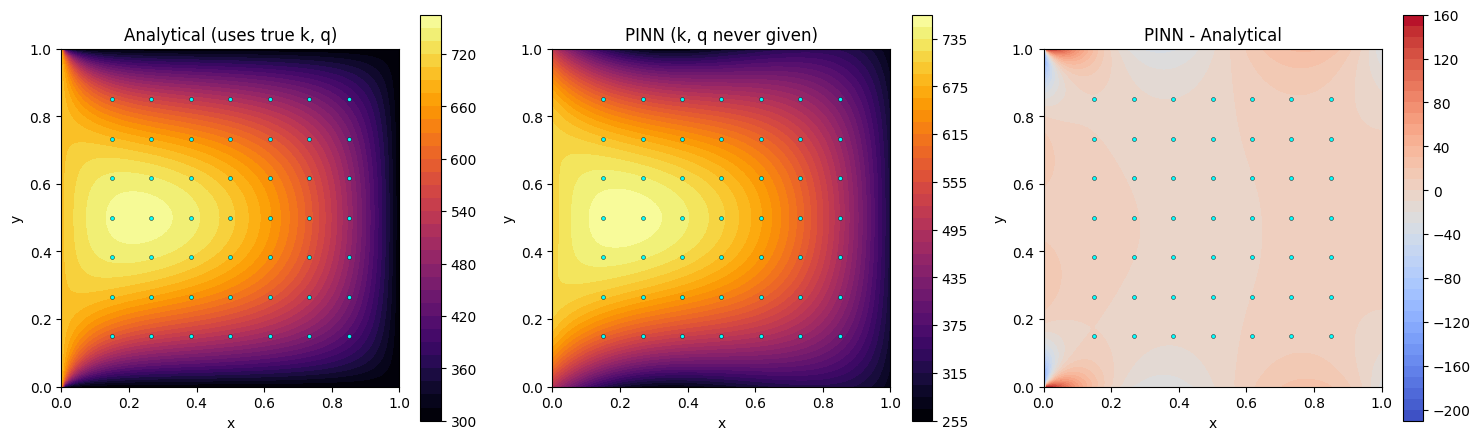

In [ ]:
with torch.no_grad():
    xg = np.linspace(0, 1, 101); yg = np.linspace(0, 1, 101)
    Xg, Yg = np.meshgrid(xg, yg)
    pts = torch.tensor(np.stack([Xg.ravel(), Yg.ravel()], 1), dtype=torch.float32)
    T_pinn = (T_ref + dT_scale*net(pts).squeeze(-1).numpy()).reshape(Xg.shape)

T_exact = np.array([[T_analytical(x, y, N=200) for x in xg] for y in yg])
err = T_pinn - T_exact
print(f"max |error| = {np.max(np.abs(err)):.1f} K")
print(f"relative L2 error of the reconstructed field = {np.linalg.norm(err)/np.linalg.norm(T_exact):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15,4.5))
for ax, field, title, cmap in zip(axes, [T_exact, T_pinn, err],
        ['Analytical (uses true k, q)', 'PINN (k, q never given)', 'PINN - Analytical'],
        ['inferno', 'inferno', 'coolwarm']):
    c = ax.contourf(Xg, Yg, field, levels=40, cmap=cmap)
    plt.colorbar(c, ax=ax)
    ax.scatter(sensor_pts[:,0], sensor_pts[:,1], s=8, c='cyan', edgecolor='k', linewidth=0.3)
    ax.set_title(title); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

# Case 2: 2D Steady-State Heat Conduction without generation(Neumann + Dirichlet BC)

**Problem.** Square plate, $1\text{ m}\times1\text{ m}$, $k=10\ \text{W/m·K}$, **no volumetric generation**.

Governing equation (Laplace):
$$\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}=0,\qquad (x,y)\in(0,1)^2$$

Boundary conditions(Neumann + Dirichlet) :
$$-k\left.\frac{\partial T}{\partial n}\right|_{x=0} = q_0 = 1000\ \text{W/m}^2\ \text{(applied into the plate)}, \qquad T(1,y)=T(x,0)=T(x,1)=100\text{ K}$$

**Inverse Problem .** Given only a handful of noisy interior temperature readings, and the fact that three sides are held at a *known* 100 K, can a PINN recover the flux/conductivity ratio $Q:=q_0/k$ — without ever being told $q_0$ or $k$?



In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)

k_true = 10.0
q0_true = 1000.0
T_other = 100.0
Q_true = q0_true / k_true    # 100 K/m

print(f"Q_true = q0/k = {Q_true:.1f} K/m")

Q_true = q0/k = 100.0 K/m


## Analytical Solution

In [ ]:
def T_analytical(x, y, Q=Q_true, N=300):
    T = T_other
    for n in range(1, N+1, 2):          # odd n only
        a, b = n*np.pi*(1-x), n*np.pi
        ratio = np.exp(a-b) * (1-np.exp(-2*a)) / (1+np.exp(-2*b))   # stable sinh(a)/cosh(b)
        A_n = 4*Q/(n**2*np.pi**2)
        T += A_n * ratio * np.sin(n*np.pi*y)
    return T

print(f"T(0, 0.5) = {T_analytical(0.0, 0.5):.2f} K   (hottest point, at the flux edge)")
print(f"T(0.5, 0.5) = {T_analytical(0.5, 0.5):.2f} K   (center)")

T(0, 0.5) = 136.97 K   (hottest point, at the flux edge)
T(0.5, 0.5) = 108.01 K   (center)


## Q being estimated

$k$ and $q_0$ enter this problem through the boundary conditions . The PDE itself, $T_{xx}+T_{yy}=0$, contains neither. The three Dirichlet edges are fixed numbers (100 K), no $k$ or $q_0$ there either. The **only** place either constant appears is the Neumann condition:
$$-k\left.\frac{\partial T}{\partial x}\right|_{x=0} = q_0 \;\Longrightarrow\; \left.\frac{\partial T}{\partial x}\right|_{x=0} = -\frac{q_0}{k} = -Q$$

$k$ and $q_0$ only ever appear as this one ratio, $Q$. There can be, infinitely many $(k,q_0)$ pairs sharing the same $Q$ — $(10,1000)$, $(5,500)$, $(20,2000)$, ... — produce the identical temperature field everywhere. So $Q$, not $k$ and $q_0$ separately, is what gets estimated here.


## Interior Sparse Points

 a $7\times7$ grid of points strictly inside the plate, each with a single noisy reading. Nothing on the boundary, nowhere near the corners, and never the full $101\times101$ field.

In [ ]:
rng = np.random.default_rng(42)

n_s = 7
xs_s = np.linspace(0.15, 0.85, n_s)
ys_s = np.linspace(0.15, 0.85, n_s)
Xs_grid, Ys_grid = np.meshgrid(xs_s, ys_s)
sensor_pts = np.stack([Xs_grid.ravel(), Ys_grid.ravel()], axis=1)

T_clean = np.array([T_analytical(x, y) for x, y in sensor_pts])
noise_sigma = 0.3   # K
T_noisy = T_clean + rng.normal(0, noise_sigma, size=T_clean.shape)

print(f"{len(sensor_pts)} sensor points, T range [{T_clean.min():.1f}, {T_clean.max():.1f}] K")

49 sensor points, T range [100.8, 124.2] K


## Non-Dimensionalisation

Case 1 could nondimensionalize using $\Delta T=T_{\text{left}}-T_{\text{other}}=400$ K — a jump between two *known* boundary values. Here all three Dirichlet edges equal the **same** value (100 K), so there is no known jump to build a scale from, and (as in Case 1) the physically "correct" scale $q_0L/k$ can't be used either, since it needs the very quantity being solved for.

Instead, use the empirical spread of the sensor readings themselves — a perfectly ordinary thing to do in a real inverse problem when no physical scale is available up front:
$$\Delta T := \text{std}(T_{\text{sensor readings}}), \qquad \theta = \frac{T-T_{\text{other}}}{\Delta T}$$

In [ ]:
T_ref = T_other
dT_scale = float(np.std(T_noisy))
print(f"dT_scale (from sensor data) = {dT_scale:.3f} K")

sensor_pts_t   = torch.tensor(sensor_pts, dtype=torch.float32)
theta_sensor_t = torch.tensor((T_noisy - T_ref)/dT_scale, dtype=torch.float32)

dT_scale (from sensor data) = 6.401 K


## Network

$Q_\theta := Q/\Delta T$ is the dimensionless flux target, declared as a plain `nn.Parameter` — it enters only the **Neumann** loss term below, not the PDE residual (since there's no source term for it to sit inside).

In [ ]:
n_side = 25
xs = torch.linspace(0, 1, n_side)

X_dirichlet = torch.cat([
    torch.stack([torch.ones(n_side), xs], 1),    # right
    torch.stack([xs, torch.zeros(n_side)], 1),   # bottom
    torch.stack([xs, torch.ones(n_side)], 1),    # top
], dim=0)
theta_dirichlet = torch.zeros(X_dirichlet.shape[0])   # all equal T_ref, so theta=0

X_neumann = torch.stack([torch.zeros(n_side), xs], 1).requires_grad_(True)   # left edge

n_f = 30
gx, gy = torch.meshgrid(torch.linspace(0.02, 0.98, n_f), torch.linspace(0.02, 0.98, n_f), indexing='ij')
X_f = torch.stack([gx.reshape(-1), gy.reshape(-1)], dim=1).requires_grad_(True)

net = nn.Sequential(nn.Linear(2, 24), nn.Tanh(), nn.Linear(24, 1))
Q_theta = nn.Parameter(torch.tensor(0.0))   # trainable: no prior knowledge of Q

## Training

There are 4 loss terms : Dirichlet (known), sensor data (noisy, sparse), Neumann (the one with $Q_\theta$), and the PDE residual — and try the direct analogue of Case 1's training setup

$$\mathcal L = \text{MSE}(\hat\theta_{\text{Dirichlet}}) + \text{MSE}(\hat\theta_{\text{sensor}}-\theta_{\text{sensor}}) + \text{MSE}(\hat\theta_x(\text{left})+Q_\theta) + \text{MSE}(\hat\theta_{xx}+\hat\theta_{yy})$$

We notice that $\theta\equiv0$ everywhere, with $Q_\theta=0$, is an exact solution to three of the four loss terms simultaneously as it satisfies the Dirichlet loss (all those edges want $\theta=0$ anyway), the Neumann loss (zero flux matches zero $Q_\theta$), and the PDE residual (a constant function is harmonic). The **only** loss term that objects to this degenerate all-zero solution is the sensor data term, . That makes $\theta\equiv0,\,Q_\theta=0$ a strong attractor that gradient descent has to be pulled *away* from by the sensor data loss alone.

The practical fix is to **upweight the sensor data loss** so it can compete with the other three terms' pull back toward the trivial solution:
$$\mathcal L = \text{MSE}_{\text{Dirichlet}} + 20\cdot\text{MSE}_{\text{data}} + \text{MSE}_{\text{Neumann}} + \text{MSE}_{\text{PDE}}$$


In [ ]:
optimizer = torch.optim.Adam([
    {'params': net.parameters(), 'lr': 2e-3},
    {'params': [Q_theta],        'lr': 0.5},
])
DATA_WEIGHT = 20.0

n_iters = 150_000
for it in range(n_iters + 1):
    optimizer.zero_grad()

    th_d = net(X_dirichlet).squeeze(-1)
    loss_d = ((th_d - theta_dirichlet)**2).mean()

    th_s = net(sensor_pts_t).squeeze(-1)
    loss_data = ((th_s - theta_sensor_t)**2).mean()

    th_n = net(X_neumann).squeeze(-1)
    grad_n = torch.autograd.grad(th_n.sum(), X_neumann, create_graph=True)[0]
    loss_n = ((grad_n[:,0] + Q_theta)**2).mean()

    th_f = net(X_f).squeeze(-1)
    g1 = torch.autograd.grad(th_f.sum(), X_f, create_graph=True)[0]
    th_xx = torch.autograd.grad(g1[:,0].sum(), X_f, create_graph=True)[0][:,0]
    th_yy = torch.autograd.grad(g1[:,1].sum(), X_f, create_graph=True)[0][:,1]
    loss_pde = ((th_xx + th_yy)**2).mean()

    loss = loss_d + DATA_WEIGHT*loss_data + loss_n + loss_pde
    loss.backward()
    optimizer.step()

    if it % 15_000 == 0:
        Q_est = Q_theta.item() * dT_scale
        print(f"{it:7d}  d={loss_d.item():.5f}  data={loss_data.item():.5f}  "
              f"n={loss_n.item():.5f}  pde={loss_pde.item():.5f}  "
              f"Q_est={Q_est:.2f} (true {Q_true:.1f})")

      0  d=0.16344  data=1.63251  n=0.00430  pde=0.00284  Q_est=3.20 (true 100.0)


  15000  d=0.20995  data=0.00492  n=0.02141  pde=0.07268  Q_est=90.41 (true 100.0)


  30000  d=0.18513  data=0.00419  n=0.01643  pde=0.06663  Q_est=92.03 (true 100.0)


  45000  d=0.17432  data=0.00392  n=0.01488  pde=0.06218  Q_est=92.77 (true 100.0)


  60000  d=0.16032  data=0.00364  n=0.01623  pde=0.06332  Q_est=93.24 (true 100.0)


...

  90000  d=0.14594  data=0.00330  n=0.00919  pde=0.05337  Q_est=94.40 (true 100.0)


 105000  d=0.14395  data=0.00324  n=0.00866  pde=0.05368  Q_est=94.49 (true 100.0)


 120000  d=0.14260  data=0.00321  n=0.00833  pde=0.05379  Q_est=94.53 (true 100.0)


 135000  d=0.14155  data=0.00318  n=0.00814  pde=0.05380  Q_est=94.61 (true 100.0)


 150000  d=0.14070  data=0.00316  n=0.00801  pde=0.05369  Q_est=94.65 (true 100.0)


## Results and Plots

In [ ]:
Q_recovered = Q_theta.item() * dT_scale
rel_err = abs(Q_recovered - Q_true) / Q_true * 100
print(f"Recovered Q = q0/k = {Q_recovered:.2f} K/m")
print(f"True Q             = {Q_true:.2f} K/m")
print(f"Relative error     = {rel_err:.1f}%")

Recovered Q = q0/k = 94.65 K/m
True Q             = 100.00 K/m
Relative error     = 5.3%


max |error| = 10.82 K
relative L2 error of the reconstructed field = 0.0082


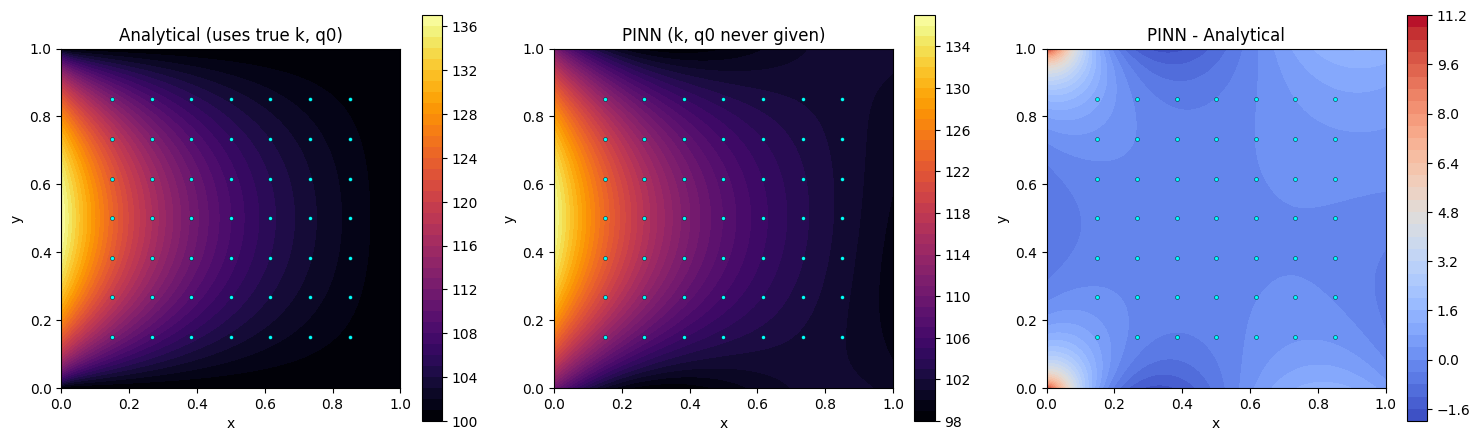

In [ ]:
with torch.no_grad():
    xg = np.linspace(0, 1, 101); yg = np.linspace(0, 1, 101)
    Xg, Yg = np.meshgrid(xg, yg)
    pts = torch.tensor(np.stack([Xg.ravel(), Yg.ravel()], 1), dtype=torch.float32)
    T_pinn = (T_ref + dT_scale*net(pts).squeeze(-1).numpy()).reshape(Xg.shape)

T_exact = np.array([[T_analytical(x, y, N=300) for x in xg] for y in yg])
err = T_pinn - T_exact
print(f"max |error| = {np.max(np.abs(err)):.2f} K")
print(f"relative L2 error of the reconstructed field = {np.linalg.norm(err)/np.linalg.norm(T_exact):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15,4.5))
for ax, field, title, cmap in zip(axes, [T_exact, T_pinn, err],
        ['Analytical (uses true k, q0)', 'PINN (k, q0 never given)', 'PINN - Analytical'],
        ['inferno', 'inferno', 'coolwarm']):
    c = ax.contourf(Xg, Yg, field, levels=40, cmap=cmap)
    plt.colorbar(c, ax=ax)
    ax.scatter(sensor_pts[:,0], sensor_pts[:,1], s=8, c='cyan', edgecolor='k', linewidth=0.3)
    ax.set_title(title); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_aspect('equal')
plt.tight_layout(); plt.show()

# Case 3: 2D Steady-State Heat Conduction without generation(Neumann +  Robin BC)

**Problem.** Square plate, $1\text{ m}\times1\text{ m}$, $k=10\ \text{W/m·K}$, no volumetric generation.

Governing equation (pure Laplace):
$$\frac{\partial^2 T}{\partial x^2}+\frac{\partial^2 T}{\partial y^2}=0$$

Boundary conditions:
- Left ($x=0$): uniform applied flux $q_0=500\ \text{W/m}^2$ (Neumann)
- Right, top, bottom: convection to ambient air, $h=15\ \text{W/m}^2\text{K}$, $T_\infty=300$ K (Robin)

**Inverse problem.** We are *not* told $k$, $q_0$, or $h$. We only have a handful of noisy interior temperature readings. As in Cases 1 and 2, we don't try to recover each constant separately — we find out which combinations of them the physics actually lets us identify, and recover only those. This time there turn out to be **two** independent identifiable ratios instead of one.

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)

k_true  = 10.0
q0_true = 500.0
h_true  = 15.0
T_inf   = 300.0
L       = 1.0

Q_true  = q0_true / k_true   # 50   -- flux ratio, known only for grading
Bi_true = h_true * L / k_true  # 1.5 -- Biot number, known only for grading

print(f"Q_true  = q0/k = {Q_true:.2f}")
print(f"Bi_true = hL/k = {Bi_true:.2f}")

Q_true  = q0/k = 50.00
Bi_true = hL/k = 1.50


## Analytical Solution

In [ ]:
from scipy.optimize import brentq

def eig_eq(mu, Bi):
    return mu*np.tan(mu/2) - Bi

def get_eigs(Bi, N_modes=40):
    mus = []
    lo = 1e-6
    for kk in range(N_modes):
        hi = (2*kk+1)*np.pi - 1e-6
        xs = np.linspace(lo, hi, 3000)
        vals = eig_eq(xs, Bi)
        for i in range(len(xs)-1):
            if np.isfinite(vals[i]) and np.isfinite(vals[i+1]) and np.sign(vals[i]) != np.sign(vals[i+1]):
                r = brentq(eig_eq, xs[i], xs[i+1], args=(Bi,))
                if not mus or r - mus[-1] > 1e-4:
                    mus.append(r)
        lo = hi + 2e-6
    return np.array(mus)

def Cn(mu, Bi):
    return -(Bi*np.cosh(mu) + mu*np.sinh(mu)) / (mu*np.cosh(mu) + Bi*np.sinh(mu))

def phi(mu, x, c):
    return np.cosh(mu*x) + c*np.sinh(mu*x)

def gamma(mu, Q):
    return -4*Q*np.sin(mu/2) / (mu + np.sin(mu))

_mus = get_eigs(Bi_true)
_Cs  = Cn(_mus, Bi_true)
_Ds  = gamma(_mus, Q_true) / (_Cs*_mus)

def T_analytical(x, y, Q=Q_true, Bi=Bi_true, mus=_mus, Cs=_Cs, Ds=_Ds):
    T = T_inf
    for mu, c, D in zip(mus, Cs, Ds):
        T += D*phi(mu, x, c)*np.cos(mu*(y - 0.5))
    return T

print(f"T(0, 0.5)   = {T_analytical(0.0, 0.5):.2f} K   (hottest point, on the flux edge)")
print(f"T(0.5, 0.5) = {T_analytical(0.5, 0.5):.2f} K")
print(f"T(1, 0.5)   = {T_analytical(1.0, 0.5):.2f} K   (coolest point, convective edge)")

T(0, 0.5)   = 334.80 K   (hottest point, on the flux edge)
T(0.5, 0.5) = 316.47 K
T(1, 0.5)   = 307.71 K   (coolest point, convective edge)


## Step 2 — why *two* ratios, not one, are identifiable here

Look at every place $k$, $q_0$, $h$ enter the problem:

- **Interior PDE**: $T_{xx}+T_{yy}=0$. No source term — none of the three constants appear here at all (same as Case 2).
- **Neumann edge** ($x=0$): $-k\,T_x = q_0 \;\Rightarrow\; T_x = -q_0/k$. Only the ratio $Q=q_0/k$ appears.
- **Robin edges** ($x=1$, $y=0$, $y=1$): $-k\,T_n = h(T-T_\infty) \;\Rightarrow\; T_n = -(h/k)(T-T_\infty)$. Only the ratio $Bi=hL/k$ appears (with $L=1$ here, $Bi=h/k$ numerically).

$Q$ and $Bi$ are **different** combinations of $k$ with $q_0$ and $h$ respectively, and either one can change independently without the other having to — e.g. doubling $q_0$ changes $Q$ but leaves $Bi$ untouched. So unlike Case 1/2's single ratio, this problem has **two** independent identifiable quantities, and that's the most we can ever recover from temperature data alone: $k$, $q_0$, $h$ individually are still each unrecoverable (any $(k,q_0,h)$ triple giving the same $(Q,Bi)$ produces the identical temperature field), but the *pair* $(Q,Bi)$ is.

## Interior Sparse Data

Same recipe as Cases 1 and 2: a $7\times7$ grid strictly inside the plate (never on a boundary), one noisy reading per point.

In [ ]:
rng = np.random.default_rng(42)

n_s = 7
xs_s = np.linspace(0.15, 0.85, n_s)
ys_s = np.linspace(0.15, 0.85, n_s)
Xs_grid, Ys_grid = np.meshgrid(xs_s, ys_s)
sensor_pts = np.stack([Xs_grid.ravel(), Ys_grid.ravel()], axis=1)

T_clean = np.array([T_analytical(x, y) for x, y in sensor_pts])
noise_sigma = 0.4   # K
T_noisy = T_clean + rng.normal(0, noise_sigma, size=T_clean.shape)

print(f"{len(sensor_pts)} interior sensors, T range {T_clean.min():.1f}-{T_clean.max():.1f} K, noise sigma={noise_sigma} K")

49 interior sensors, T range 308.3-327.9 K, noise sigma=0.4 K


## Step 4 — nondimensionalization

As in Case 2, there's no known boundary *jump* to build a temperature scale from (the boundary conditions here are a flux and a convective law, not two different fixed temperatures), so we use the empirical spread of the sensor readings themselves: $\Delta T = \text{std}(T_{\text{noisy}})$, and $\theta = (T-T_\infty)/\Delta T$.

This scale choice matters differently for the two unknowns:
- **$Bi$ is scale-invariant.** The Robin condition $T_n=-Bi(T-T_\infty)$ becomes, after substituting $T=T_\infty+\Delta T\cdot\theta$, exactly $\theta_n = -Bi\,\theta$ — $\Delta T$ cancels. Whatever trainable parameter satisfies this residual **is** $Bi$ directly, no rescaling needed at the end.
- **$Q$ is not.** The Neumann condition $T_x=-Q$ becomes $\theta_x = -Q/\Delta T$. So the parameter the network actually learns is $Q_\theta = Q/\Delta T$, and we must multiply back by $\Delta T$ at the end to recover physical $Q$ — exactly like Case 2.

In [ ]:
T_ref = T_inf
dT_scale = float(np.std(T_noisy))
print(f"dT_scale (from sensor data) = {dT_scale:.4f} K")

sensor_pts_t   = torch.tensor(sensor_pts, dtype=torch.float32)
theta_sensor_t = torch.tensor((T_noisy - T_ref)/dT_scale, dtype=torch.float32)

dT_scale (from sensor data) = 5.8640 K


## Network

$Q_\theta$ enters only the Neumann loss (left edge, $x=0$). $Bi_\theta$ enters all three Robin losses (right, bottom, top edges) — the *same* scalar in every one of them, since it's a single physical property of the plate. Neither appears in the PDE residual (there's no source term for either to sit inside), so both live purely in the boundary conditions, exactly like $Q$ did in Case 2.

In [ ]:
net = nn.Sequential(nn.Linear(2, 24), nn.Tanh(), nn.Linear(24, 1))

# Nonzero initial values: at Q=0, Bi=0 the trivial field theta=0 satisfies every boundary
# residual and the PDE simultaneously (see Step 6), which also makes the loss's gradient
# w.r.t. both parameters vanish there -- starting away from that point avoids getting stuck.
Q_theta  = nn.Parameter(torch.tensor(5.0))
Bi_theta = nn.Parameter(torch.tensor(1.0))

n_side = 60
xs = torch.linspace(0, 1, n_side)

X_neumann     = torch.stack([torch.zeros(n_side), xs], 1).requires_grad_(True)   # x=0, flux edge
X_robin_right = torch.stack([torch.ones(n_side),  xs], 1).requires_grad_(True)   # x=1
X_robin_bot   = torch.stack([xs, torch.zeros(n_side)], 1).requires_grad_(True)   # y=0
X_robin_top   = torch.stack([xs, torch.ones(n_side)],  1).requires_grad_(True)   # y=1

N_f = 1500
X_f = torch.rand(N_f, 2, requires_grad=True)   # interior collocation points for the PDE

## Step 6 — training: the same trivial-solution attractor, now for both parameters

$$
\mathcal L = \underbrace{\frac{1}{N_N}\sum_{i=1}^{N_N}\big(\theta_x(0,y_i) + Q_\theta\big)^2}_{\text{Neumann (flux edge, }x=0\text{)}} \;+\; \underbrace{\frac{1}{N_R}\sum_{i=1}^{N_R}\big(\theta_n(\mathbf x_i) + Bi_\theta\,\theta(\mathbf x_i)\big)^2}_{\text{Robin (three convective edges)}} \;+\; \lambda_{\text{data}}\underbrace{\frac{1}{N_s}\sum_{i=1}^{N_s}\big(\theta(\mathbf x_i^s) - \theta_i^{\text{noisy}}\big)^2}_{\text{sensor data}} \;+\; \underbrace{\frac{1}{N_f}\sum_{i=1}^{N_f}\big(\theta_{xx} + \theta_{yy}\big)^2\Big|_{\mathbf x_i^f}}_{\text{PDE residual}}
$$

where $\theta_n$ is the outward-normal derivative ($\theta_x$ at $x=1$, $-\theta_y$ at $y=0$, $\theta_y$ at $y=1$), $Q_\theta$ and $Bi_\theta$ are the two trainable parameters, and $\lambda_{\text{data}}=30$.

In [ ]:
optimizer = torch.optim.Adam([
    {'params': net.parameters(), 'lr': 3e-3},
    {'params': [Q_theta],        'lr': 0.3},
    {'params': [Bi_theta],       'lr': 0.05},
])
DATA_WEIGHT = 30.0

history = {'total': [], 'bc': [], 'data': [], 'pde': []}

n_iters = 30_000
for it in range(n_iters + 1):
    optimizer.zero_grad()

    th_n = net(X_neumann).squeeze(-1)
    grad_n = torch.autograd.grad(th_n.sum(), X_neumann, create_graph=True)[0]
    loss_neumann = ((grad_n[:, 0] + Q_theta)**2).mean()

    # x=1: outward normal +x -> theta_x + Bi*theta = 0
    th_r = net(X_robin_right).squeeze(-1)
    grad_r = torch.autograd.grad(th_r.sum(), X_robin_right, create_graph=True)[0]
    loss_robin_r = ((grad_r[:, 0] + Bi_theta*th_r)**2).mean()

    # y=0: outward normal -y -> theta_y - Bi*theta = 0
    th_b = net(X_robin_bot).squeeze(-1)
    grad_b = torch.autograd.grad(th_b.sum(), X_robin_bot, create_graph=True)[0]
    loss_robin_b = ((grad_b[:, 1] - Bi_theta*th_b)**2).mean()

    # y=1: outward normal +y -> theta_y + Bi*theta = 0
    th_t = net(X_robin_top).squeeze(-1)
    grad_t = torch.autograd.grad(th_t.sum(), X_robin_top, create_graph=True)[0]
    loss_robin_t = ((grad_t[:, 1] + Bi_theta*th_t)**2).mean()

    loss_bc = loss_neumann + loss_robin_r + loss_robin_b + loss_robin_t

    th_s = net(sensor_pts_t).squeeze(-1)
    loss_data = ((th_s - theta_sensor_t)**2).mean()

    th_f = net(X_f).squeeze(-1)
    g1 = torch.autograd.grad(th_f.sum(), X_f, create_graph=True)[0]
    th_xx = torch.autograd.grad(g1[:, 0].sum(), X_f, create_graph=True)[0][:, 0]
    th_yy = torch.autograd.grad(g1[:, 1].sum(), X_f, create_graph=True)[0][:, 1]
    loss_pde = ((th_xx + th_yy)**2).mean()

    loss = loss_bc + DATA_WEIGHT*loss_data + loss_pde
    loss.backward()
    optimizer.step()

    if it % 200 == 0:
        history['total'].append(loss.item())
        history['bc'].append(loss_bc.item())
        history['data'].append(loss_data.item())
        history['pde'].append(loss_pde.item())

    if it % 5000 == 0:
        Q_phys = Q_theta.item()*dT_scale
        print(f"it={it:6d}  loss={loss.item():.4e}  Q={Q_phys:7.3f}  Bi={Bi_theta.item():.3f}  "
              f"data={loss_data.item():.4e}  bc={loss_bc.item():.4e}  pde={loss_pde.item():.4e}")

it=     0  loss=2.2601e+02  Q= 27.561  Bi=0.950  data=6.7076e+00  bc=2.4781e+01  pde=2.8707e-03


it=  5000  loss=3.1694e-01  Q= 47.146  Bi=1.360  data=3.2793e-03  bc=1.8368e-01  pde=3.4886e-02


it= 10000  loss=1.5186e-01  Q= 49.096  Bi=1.452  data=2.7421e-03  bc=4.9420e-02  pde=2.0175e-02


it= 15000  loss=1.1519e-01  Q= 49.560  Bi=1.475  data=2.7175e-03  bc=2.7220e-02  pde=6.4470e-03


it= 20000  loss=1.1066e-01  Q= 49.662  Bi=1.479  data=2.7151e-03  bc=2.3471e-02  pde=5.7403e-03


it= 25000  loss=1.0814e-01  Q= 49.647  Bi=1.479  data=2.7081e-03  bc=2.1419e-02  pde=5.4823e-03


it= 30000  loss=1.0715e-01  Q= 49.657  Bi=1.479  data=2.7070e-03  bc=2.0626e-02  pde=5.3151e-03


## Loss curves

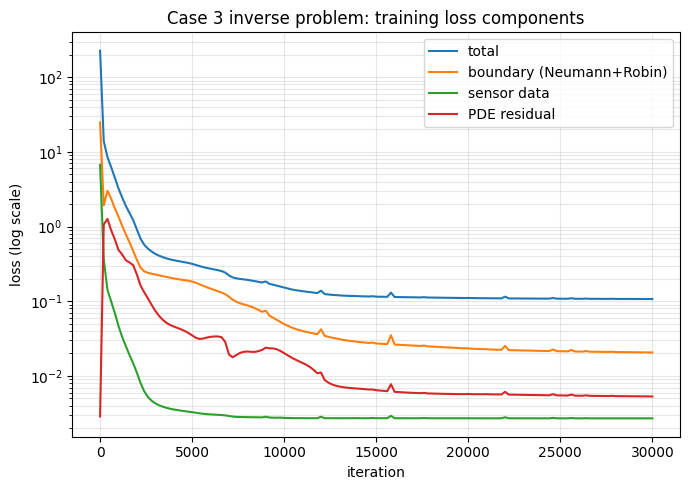

In [ ]:
iters_logged = np.arange(len(history['total']))*200

plt.figure(figsize=(7,5))
plt.semilogy(iters_logged, history['total'], label='total')
plt.semilogy(iters_logged, history['bc'],    label='boundary (Neumann+Robin)')
plt.semilogy(iters_logged, history['data'],  label='sensor data')
plt.semilogy(iters_logged, history['pde'],   label='PDE residual')
plt.xlabel('iteration'); plt.ylabel('loss (log scale)')
plt.title('Case 3 inverse problem: training loss components')
plt.legend(); plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig('case3_loss_curve.png', dpi=110)
plt.show()

## Step 8 — result

In [ ]:
Q_recovered  = Q_theta.item()*dT_scale
Bi_recovered = Bi_theta.item()

Q_err  = abs(Q_recovered - Q_true)/Q_true*100
Bi_err = abs(Bi_recovered - Bi_true)/Bi_true*100

print(f"Recovered Q  = q0/k = {Q_recovered:.3f}   (true {Q_true:.2f}, error {Q_err:.2f}%)")
print(f"Recovered Bi = hL/k = {Bi_recovered:.3f}   (true {Bi_true:.2f}, error {Bi_err:.2f}%)")

Recovered Q  = q0/k = 49.657   (true 50.00, error 0.69%)
Recovered Bi = hL/k = 1.479   (true 1.50, error 1.38%)


max |error|      = 0.129 K
relative L2 error = 0.0030


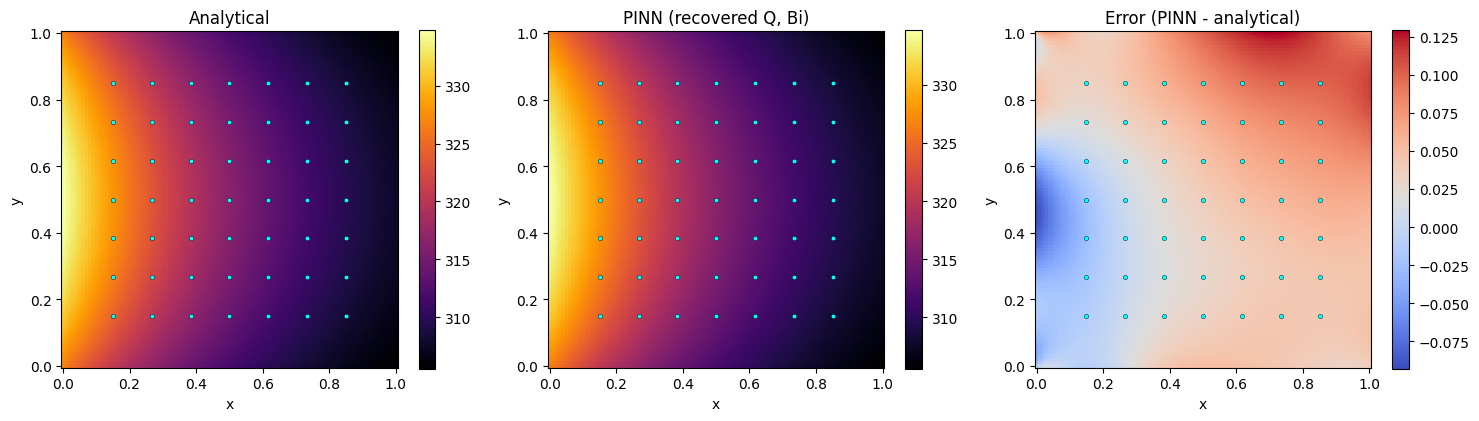

In [ ]:
with torch.no_grad():
    xg = np.linspace(0, 1, 101); yg = np.linspace(0, 1, 101)
    Xg, Yg = np.meshgrid(xg, yg)
    pts_t = torch.tensor(np.stack([Xg.ravel(), Yg.ravel()], 1), dtype=torch.float32)
    T_pinn = (T_ref + dT_scale*net(pts_t).squeeze(-1).numpy()).reshape(Xg.shape)

T_exact = np.array([[T_analytical(x, y) for x in xg] for y in yg])
err = T_pinn - T_exact
rel_l2 = np.linalg.norm(err)/np.linalg.norm(T_exact - T_inf)
print(f"max |error|      = {np.abs(err).max():.3f} K")
print(f"relative L2 error = {rel_l2:.4f}")

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, Z, title in zip(axs, [T_exact, T_pinn, err],
                         ['Analytical', 'PINN (recovered Q, Bi)', 'Error (PINN - analytical)']):
    im = ax.pcolormesh(Xg, Yg, Z, shading='auto', cmap='coolwarm' if title.startswith('Error') else 'inferno')
    plt.colorbar(im, ax=ax)
    ax.scatter(sensor_pts[:,0], sensor_pts[:,1], s=10, c='cyan', edgecolor='k', linewidth=0.3)
    ax.set_title(title); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_aspect('equal')
plt.tight_layout()
plt.savefig('case3_field_comparison.png', dpi=110)
plt.show()

##Comparison across all three inverse problems

| | Case 1 (generation) | Case 2 (Neumann/Dirichlet) | Case 3 (Neumann/Robin) |
|---|---|---|---|
| Unknown(s) recovered | $\beta=\dot q/k$ | $Q=q_0/k$ | $Q=q_0/k$ **and** $Bi=hL/k$ |
| Number of identifiable ratios | 1 | 1 | 2 (independent) |
| Where they live | inside the PDE (interior) | inside one boundary condition | both inside boundary conditions only |
| Nondimensionalization scale | known boundary jump (400 K) | empirical spread of sensor data | empirical spread of sensor data |
| Rescaling needed after training | yes ($\times\Delta T$) | yes ($\times\Delta T$) | $Q$: yes; $Bi$: no (scale-invariant) |
| Trivial-solution risk | none (parameter sits in interior PDE, always active) | yes — $\theta\equiv0,\,Q=0$ satisfies every loss but data | yes, and worse — $Bi$'s gradient *also* vanishes at $\theta\equiv0$ for any $Bi$ |
| Fix used | plain Adam, single parameter group | `DATA_WEIGHT=20`, nonzero init unnecessary (Q started at 0 anyway) | `DATA_WEIGHT=30`, **nonzero** initial values for both parameters |

The general lesson holds across all three cases: **a PINN can only ever recover the combinations of physical constants that actually appear, separably, somewhere in the governing equations or boundary conditions** — never each constant on its own — and whenever an unknown lives only in a boundary condition (rather than the interior PDE), the training needs deliberate care (data upweighting, sensible initialization) to avoid collapsing onto the trivial field that technically satisfies every other loss term.